# Clusterização com K-Modes

Esta primeira versão segue o fluxo exploratório do notebook de K-means, mas usa distância de correspondência para variáveis categóricas. A severidade PHQ e as respostas que a compõem ficam fora das features para evitar vazamento do target. Idade e razão de renda/pobreza são agrupadas em faixas; o target é usado apenas para comparar a composição dos clusters.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from kmodes.kmodes import KModes
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import OneHotEncoder
import umap

ID_COLUNA = "ID_DOMICILIO"
PESO_COLUNA = "PESO_AMOSTRAL"
COLUNA_SEVERIDADE = "SEVERIDADE_DEPRESSAO_PHQ"
TARGET = "DEPRESSAO_PHQ_SIMPLIFICADO"

COLUNAS_SINTOMAS_DEPRESSAO = [
    "FREQ_PERDA_INTERESSE_2SEM",
    "FREQ_SENTIU_DEPRIMIDO_2SEM",
    "FREQ_DIFICULDADE_DORMIR_2SEM",
    "FREQ_CANSASO_2SEM",
    "FREQ_HIPOREXIA_COMPULSAO_ALIMENTAR_2SEM",
    "FREQ_AUTOAVALIACAO_NEGTIVA_2SEM",
    "FREQ_DIFICULDADE_CONCENTRACAO_2SEM",
    "MODIFICACAO_VELOCIDADE_FALA",
    "FREQ_DEPRESSAO",
    "REMEDIO_DEPRESSAO",
    "HISTORICO_DEPRESSAO",
    "INTENSIDADE_DEPRESSAO",
]

# 1. Carregar a base e excluir severidades indefinidas antes de derivar o target.
df = pd.read_csv(Path("../4_random_forest") / "adult25_limpo.csv")
df = df.set_index(ID_COLUNA)
df = df[~df[COLUNA_SEVERIDADE].isin([-1, 5])].copy()
df[TARGET] = (df[COLUNA_SEVERIDADE] != 1).astype(int)

# 2. Separar target e peso amostral das features; o peso não é usado pelo K-Modes.
y = df[TARGET]
sample_weights = df[PESO_COLUNA]
colunas_remover = [TARGET, PESO_COLUNA, COLUNA_SEVERIDADE] + COLUNAS_SINTOMAS_DEPRESSAO
X = df.drop(columns=[coluna for coluna in colunas_remover if coluna in df.columns])

print(f"Registros para clusterização: {len(X):,}")
print(f"Features antes da preparação: {X.shape[1]}")
print("Distribuição do target (usado somente para análise):")
print(y.value_counts(normalize=True).sort_index().mul(100).round(1).rename("percentual"))

/Users/alexandreboldrin/.copilot/repos/saudemental/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Registros para clusterização: 23,619
Features antes da preparação: 58
Distribuição do target (usado somente para análise):
DEPRESSAO_PHQ_SIMPLIFICADO
0    78.8
1    21.2
Name: percentual, dtype: float64


## Preparar variáveis categóricas

O K-Modes não usa padronização nem one-hot encoding: cada coluna representa uma categoria. As duas variáveis contínuas usadas como numéricas no K-means são discretizadas para evitar uma categoria diferente para quase cada valor.

In [2]:
X_categorico = X.copy()

faixas_idade = ["0-17", "18-29", "30-44", "45-59", "60-74", "75+"]
idade_valida = X_categorico["IDADE"].where(X_categorico["IDADE"] >= 0)
X_categorico["IDADE_FAIXA"] = pd.cut(
    idade_valida,
    bins=[-1, 17, 29, 44, 59, 74, np.inf],
    labels=faixas_idade,
).astype("string").fillna("Não informado")

faixas_renda = ["<1", "1-<2", "2-<3", "3-<4", "4-<5", "5+"]
X_categorico["RAZAO_RENDA_POBREZA_FAIXA"] = pd.cut(
    X_categorico["RAZAO_RENDA_POBREZA"],
    bins=[-np.inf, 1, 2, 3, 4, 5, np.inf],
    labels=faixas_renda,
    right=False,
).astype("string").fillna("Não informado")

X_categorico = X_categorico.drop(columns=["IDADE", "RAZAO_RENDA_POBREZA"])
X_categorico = X_categorico.astype("string").fillna("Não informado")

print(f"Features categóricas: {X_categorico.shape[1]}")
print(f"Valores ausentes após preparação: {int(X_categorico.isna().sum().sum())}")
X_categorico.head()

Features categóricas: 58
Valores ausentes após preparação: 0


,SEXO,CLASSIFICACAO_URBANO_RURAL,REGIAO_GEOGRAFICA,ESTADO_CIVIL_DECLARADO,ESTADO_CIVIL,STATUS_PARENTAL,SEXO_CONJUGE,SEPARACAO_LEGAL_CONJUGAL,COJUGE_TRABALHA,FLG_IDOSO_FAMILIA,...,FREQ_AGITACAO_INQUIETA,FREQ_IRRITABILIDADE_2SEM,FREQ_MEDO_2SEM,SEVERIDADE_ANSIEDADE,FREQ_SOLITARIO,FREQUENCIA_FALHA_MEMORIA,TIPO_DIFICULDADE_COGNITIVA,QTD_DIFICULDADE_COGNITIVA,IDADE_FAIXA,RAZAO_RENDA_POBREZA_FAIXA
ID_DOMICILIO,,,,,,,,,,,,,,,,,,,,,
H012128,2,4,3,1,1,3,1,0,0,1,...,4,1,1,4,3,4,4,1,60-74,1-<2
H000617,1,4,3,3,5,3,0,0,0,1,...,1,1,1,1,2,1,1,2,60-74,4-<5
H033243,1,2,3,3,7,3,0,0,0,0,...,1,2,1,2,2,4,4,1,18-29,<1
H049140,1,2,3,1,1,3,2,0,0,1,...,1,2,1,1,2,4,4,1,60-74,5+
H012797,2,2,3,3,7,3,0,0,0,0,...,1,1,1,1,2,4,4,1,45-59,4-<5


## Diagnóstico inicial do número de clusters

A curva de custo compara o total de dissimilaridades (discordâncias) para diferentes valores de *k*. O silhouette é calculado com distância de Hamming em uma amostra para controlar o custo computacional. Para tornar a exploração mais rápida, os diagnósticos usam até 5.000 registros; a avaliação final abaixo ajusta o modelo escolhido em todos os registros.

In [3]:
def ajustar_kmodes(n_clusters, dados):
    modelo = KModes(
        n_clusters=n_clusters,
        init="Cao",
        n_init=3,
        max_iter=100,
        random_state=42,
        verbose=0,
    )
    labels = pd.Series(
        modelo.fit_predict(dados.to_numpy(dtype=str)),
        index=dados.index,
        name="cluster",
    )
    return modelo, labels, modelo.cost_


X_amostra = X_categorico.sample(n=min(5000, len(X_categorico)), random_state=42)
X_amostra_codificada = X_amostra.apply(lambda coluna: pd.factorize(coluna, sort=True)[0])

ks = range(2, 7)
custos = []
silhouettes = []

for k in ks:
    modelo_amostra, labels_amostra, custo = ajustar_kmodes(k, X_amostra)
    custos.append(custo)
    indices_silhouette = X_amostra.sample(
        n=min(1000, len(X_amostra)), random_state=42
    ).index
    dados_silhouette = X_amostra_codificada.loc[indices_silhouette]
    labels_silhouette = labels_amostra.loc[indices_silhouette]
    if 1 < labels_silhouette.nunique() < len(labels_silhouette):
        silhouette = silhouette_score(
            dados_silhouette,
            labels_silhouette,
            metric="hamming",
        )
    else:
        silhouette = np.nan
    silhouettes.append(silhouette)

pd.DataFrame({"k": list(ks), "custo": custos, "silhouette_hamming": silhouettes})

,k,custo,silhouette_hamming
0,2,97831.0,0.122296
1,3,95771.0,0.091354
2,4,91786.0,0.075487
3,5,88639.0,0.072506
4,6,89524.0,0.058623


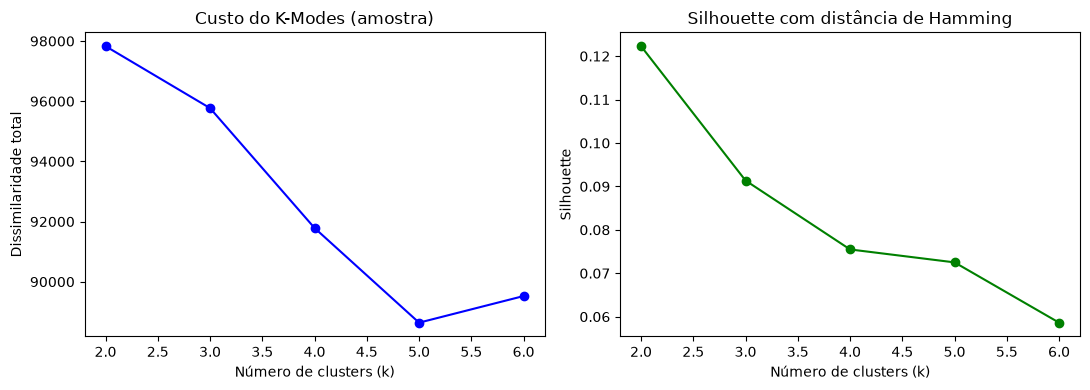

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(list(ks), custos, "bo-")
ax1.set(title="Custo do K-Modes (amostra)", xlabel="Número de clusters (k)", ylabel="Dissimilaridade total")
ax2.plot(list(ks), silhouettes, "go-")
ax2.set(title="Silhouette com distância de Hamming", xlabel="Número de clusters (k)", ylabel="Silhouette")
plt.tight_layout()
plt.show()

## Ajuste e leitura dos clusters

A análise de variação acima compara diferentes valores de k em uma amostra de 5.000 registros. Nesta execução, usamos `K_FINAL = 2`, escolhido para a comparação atual; o target não participa da formação dos clusters e é exibido somente para interpretação posterior.

Custo final: 479,613
Tamanho dos clusters:
cluster
0    19488
1     4131
Name: registros, dtype: int64

Composição do target (%) dentro de cada cluster:
target      0     1
cluster            
0        83.1  16.9
1        58.3  41.7


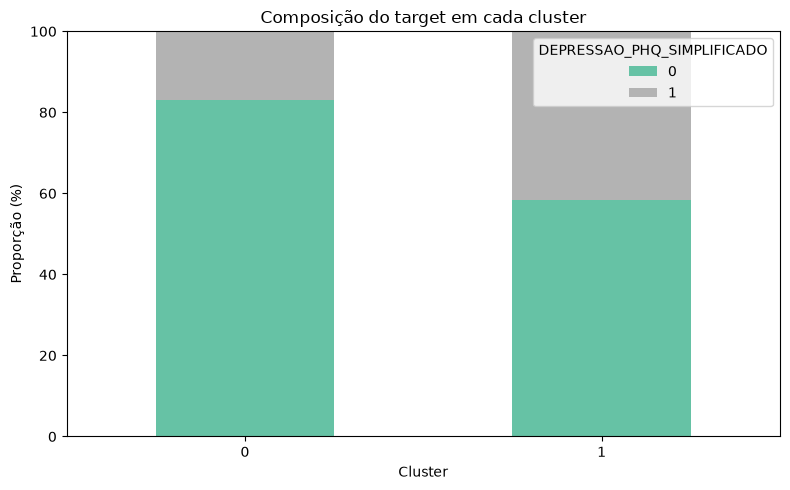

In [5]:
K_FINAL = 2
km, labels, custo_final = ajustar_kmodes(K_FINAL, X_categorico)

resultado = pd.DataFrame({"target": y, "cluster": labels})
tamanho_clusters = labels.value_counts().sort_index().rename("registros")
print(f"Custo final: {custo_final:,.0f}")
print("Tamanho dos clusters:")
print(tamanho_clusters)

contagens_target = pd.crosstab(resultado["cluster"], resultado["target"])
proporcoes_target = contagens_target.div(contagens_target.sum(axis=1), axis=0).mul(100)
print("\nComposição do target (%) dentro de cada cluster:")
print(proporcoes_target.round(1))

ax = proporcoes_target.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="Set2")
ax.set(title="Composição do target em cada cluster", xlabel="Cluster", ylabel="Proporção (%)")
ax.set_ylim(0, 100)
ax.legend(title=TARGET)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
colunas_perfil = [
    "IDADE_FAIXA",
    "RAZAO_RENDA_POBREZA_FAIXA",
    "SEXO",
    "REGIAO_GEOGRAFICA",
    "SUPORTE_SOCIAL",
    "AUTOAVALIACAO_SAUDE_GERAL",
    "CATEGORIA_IMC",
    "HISTORICO_TRANSTORNO_ANSIEDADE",
]
colunas_perfil = [coluna for coluna in colunas_perfil if coluna in X_categorico.columns]
X_cluster = X_categorico.join(labels)

def primeira_moda(coluna):
    modas = coluna.mode()
    return modas.iloc[0] if not modas.empty else "Não informado"

perfil_clusters = X_cluster.groupby("cluster")[colunas_perfil].agg(primeira_moda)
perfil_clusters.insert(0, "registros", tamanho_clusters)
print("Categorias mais frequentes em cada cluster:")
perfil_clusters

Categorias mais frequentes em cada cluster:


,registros,IDADE_FAIXA,RAZAO_RENDA_POBREZA_FAIXA,SEXO,REGIAO_GEOGRAFICA,SUPORTE_SOCIAL,AUTOAVALIACAO_SAUDE_GERAL,CATEGORIA_IMC,HISTORICO_TRANSTORNO_ANSIEDADE
cluster,,,,,,,,,
0,19488,60-74,5+,2,3,5,4,3,2
1,4131,30-44,5+,1,4,4,3,4,2


## Visualização comparativa dos perfis categóricos

Cada painel compara, para uma variável, a proporção de cada categoria dentro de cada cluster (as colunas somam 100%). O gráfico destaca até 12 variáveis com maior distância média de variação total entre clusters, entre as que têm no máximo 12 categorias; categorias com maior cardinalidade permanecem no ranking completo abaixo para não ocultar essa escolha. A escala de cores é comum a todos os painéis (0–100%). Diferenças nas linhas de um painel mostram quais categorias caracterizam cada grupo; as proporções não devem ser interpretadas como causalidade.


Ranking completo das features por diferença média entre clusters (0–100%):


,feature,categorias,variacao_total_media_pct
0,FREQ_ANSIEDADE_2SEM,5,45.9
1,FREQ_PREOCUPACAO_DESNECESSARIA_2SEM,5,45.1
2,FREQ_ANSIEDADE,6,44.6
3,FREQ_IRRITABILIDADE_2SEM,5,43.8
4,INTENSIDADE_ANSIEDADE,5,38.5
5,COJUGE_TRABALHA,3,34.4
6,IDADE_FAIXA,6,33.2
7,FREQ_DIFICULDADE_DESCANSAR_2SEM,5,32.5
8,SEVERIDADE_ANSIEDADE,5,31.6
9,ESTRESSE_FINANCEIRO_MEDICO,4,30.9


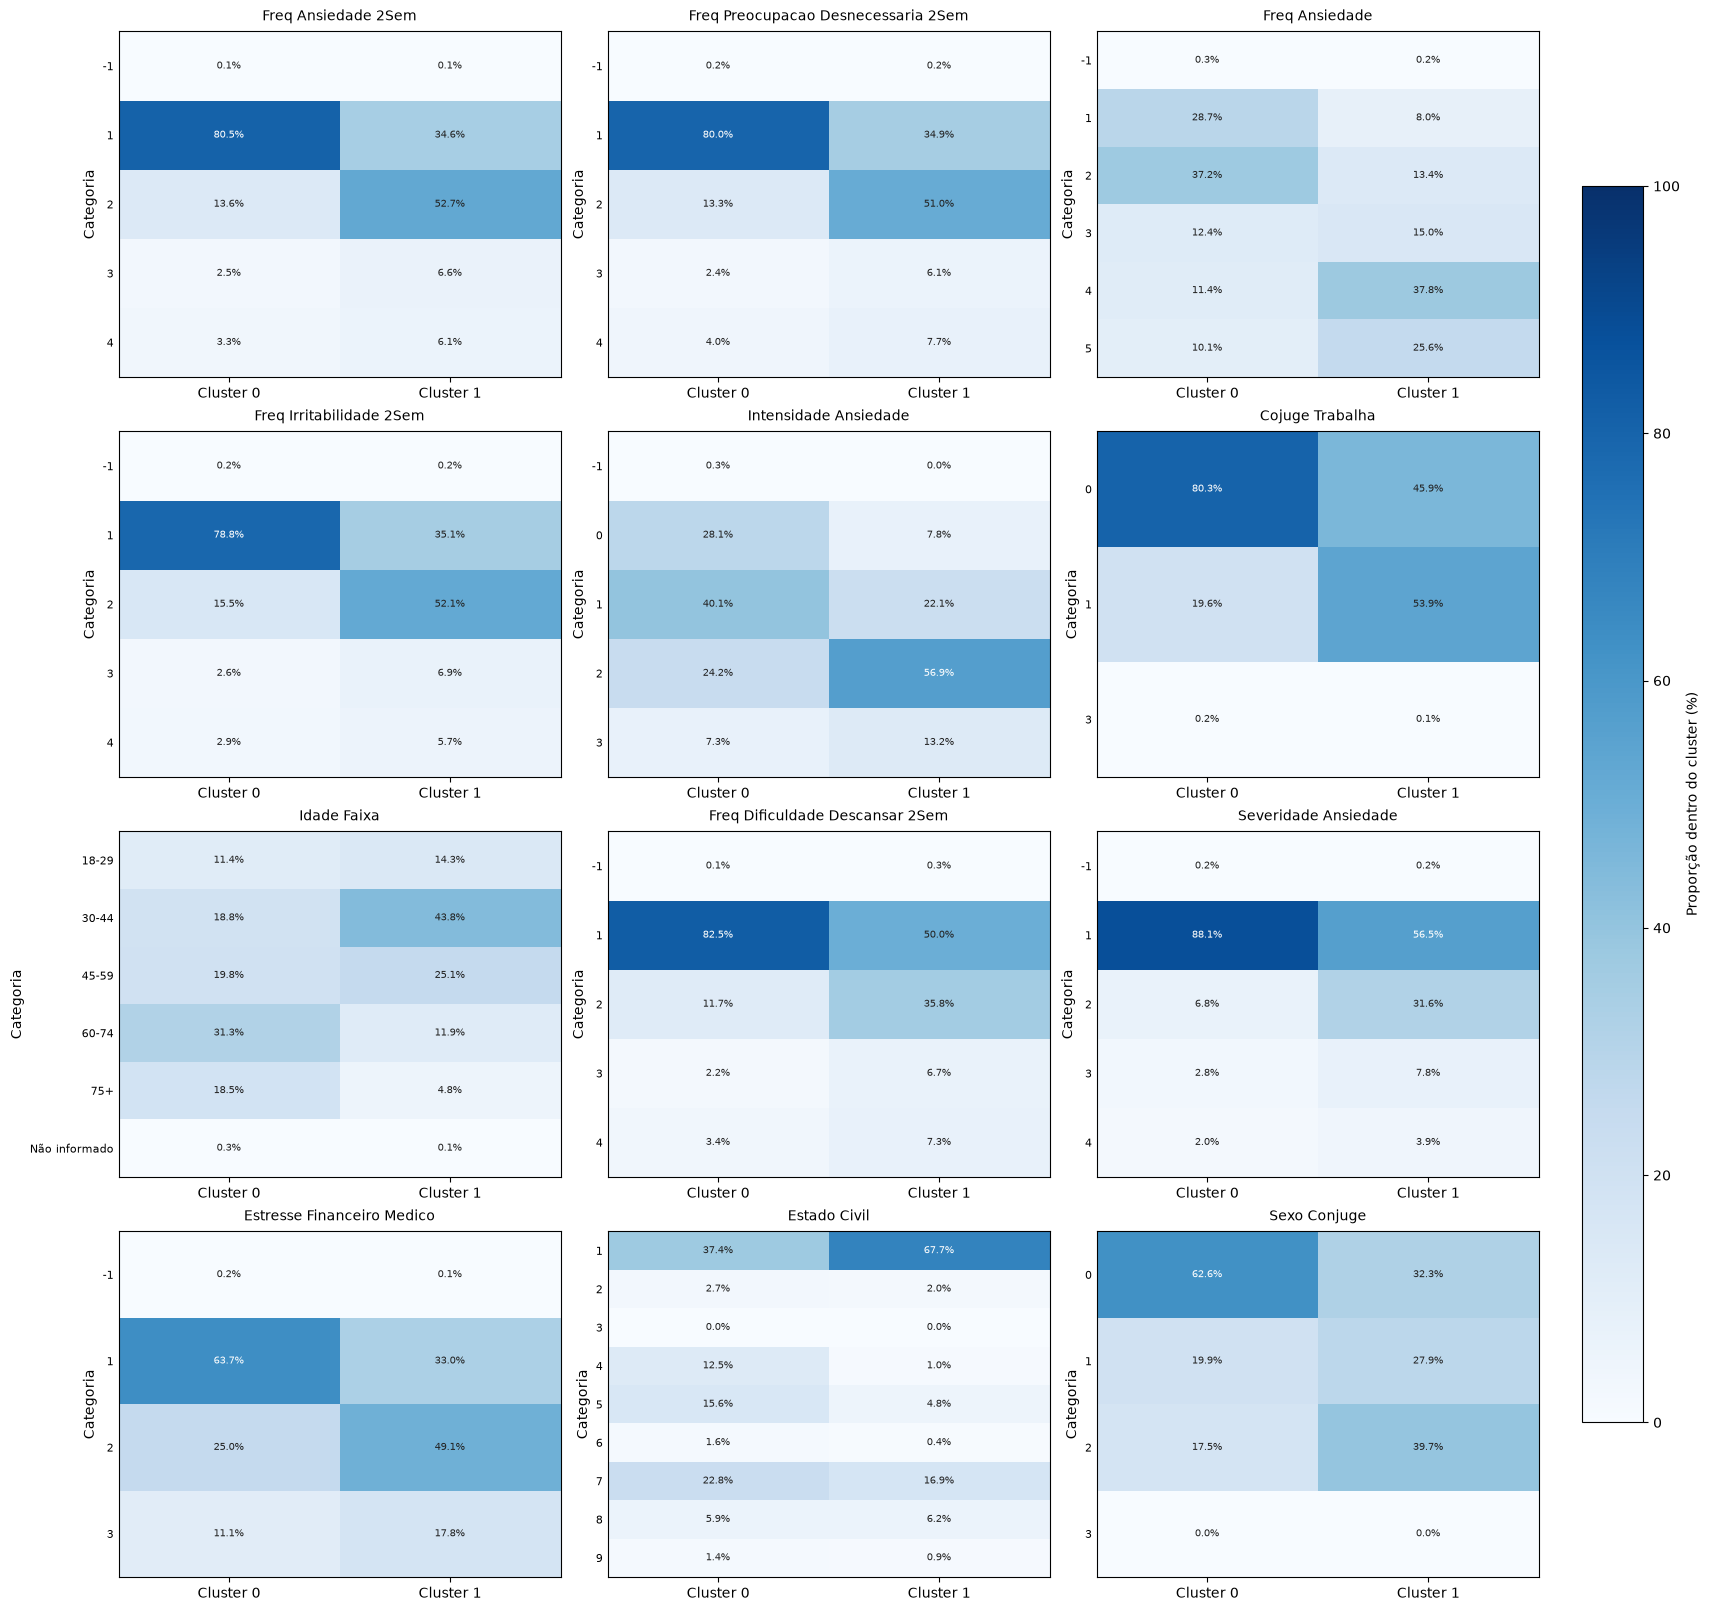

Features no gráfico: 12 de 58. O ranking completo acima inclui todas as features.


In [7]:
# Proporção de cada categoria dentro de cada cluster para todas as features.
# A distância de variação total resume quanto as distribuições diferem entre clusters.
clusters_ordenados = sorted(labels.unique())
perfis_por_feature = {}
medidas_discriminacao = []

for feature in X_categorico.columns:
    distribuicao = pd.crosstab(
        X_categorico[feature], labels,
        normalize="columns",
    ).reindex(columns=clusters_ordenados, fill_value=0)
    distribuicao.index = distribuicao.index.astype(str)
    perfis_por_feature[feature] = distribuicao

    distancias = []
    for i, cluster_a in enumerate(clusters_ordenados):
        for cluster_b in clusters_ordenados[i + 1:]:
            distancias.append(
                0.5 * (distribuicao[cluster_a] - distribuicao[cluster_b]).abs().sum()
            )
    medidas_discriminacao.append({
        "feature": feature,
        "categorias": len(distribuicao),
        "variacao_total_media_pct": 100 * np.mean(distancias),
    })

ranking_perfis = pd.DataFrame(medidas_discriminacao).sort_values(
    "variacao_total_media_pct", ascending=False
).reset_index(drop=True)
print("Ranking completo das features por diferença média entre clusters (0–100%):")
display(ranking_perfis.round({"variacao_total_media_pct": 1}))

# Limitar a complexidade visual sem excluir features do cálculo ou do ranking completo.
features_plot = (
    ranking_perfis[ranking_perfis["categorias"] <= 12]
    .head(12)["feature"]
    .tolist()
)
if not features_plot:
    raise ValueError("Nenhuma feature possui até 12 categorias para o gráfico comparativo.")

n_colunas = 3
n_linhas = int(np.ceil(len(features_plot) / n_colunas))
fig, axes = plt.subplots(
    n_linhas, n_colunas,
    figsize=(17, 4.0 * n_linhas),
    squeeze=False,
    constrained_layout=True,
)

for ax, feature in zip(axes.flat, features_plot):
    matriz = perfis_por_feature[feature] * 100
    imagem = ax.imshow(matriz.to_numpy(), cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_title(feature.replace("_", " ").title(), fontsize=10, pad=8)
    ax.set_xticks(range(len(clusters_ordenados)))
    ax.set_xticklabels([f"Cluster {cluster}" for cluster in clusters_ordenados], rotation=0, ha="center")
    ax.set_yticks(range(len(matriz.index)))
    ax.set_yticklabels(matriz.index, fontsize=8)
    ax.set_ylabel("Categoria")
    ax.tick_params(axis="y", length=0)

    for linha in range(matriz.shape[0]):
        for coluna in range(matriz.shape[1]):
            valor = matriz.iloc[linha, coluna]
            cor = "white" if valor >= 55 else "#222222"
            ax.text(coluna, linha, f"{valor:.1f}%", ha="center", va="center", color=cor, fontsize=7)

for ax in axes.flat[len(features_plot):]:
    ax.set_visible(False)

fig.colorbar(imagem, ax=axes.ravel().tolist(), label="Proporção dentro do cluster (%)", shrink=0.8, pad=0.03)
plt.show()

print(f"Features no gráfico: {len(features_plot)} de {len(X_categorico.columns)}. O ranking completo acima inclui todas as features.")


## Resumo interpretativo dos perfis (k=2)

A solução abaixo foi ajustada com `k=2` nas 23.619 observações elegíveis e 58 features categóricas. O target de depressão ficou fora das features e é apresentado somente para descrever os clusters. O codebook NHIS 2025 e as recodificações do repositório orientam a interpretação dos códigos.

| Cluster | Tamanho | Target positivo | Características que mais diferenciam os grupos |
|---|---:|---:|---|
| **0** | 19.488 (82,5%) | **16,9%** | Categoria modal de idade: 60–74 anos. Grupo majoritário, com prevalência do target abaixo da média geral. |
| **1** | 4.131 (17,5%) | **41,7%** | Categoria modal de idade: 30–44 anos. Grupo menor, com prevalência observada do target mais alta. |

No conjunto, 21,2% têm target positivo; o cluster 0 fica 4,3 pontos percentuais abaixo dessa proporção, enquanto o cluster 1 fica 20,5 pontos acima. As cinco maiores diferenças médias nas distribuições entre clusters são: frequência de ansiedade nas últimas duas semanas (45,9%), preocupação desnecessária (45,1%), frequência geral de ansiedade (44,6%), irritabilidade (43,8%) e intensidade da ansiedade (38,5%). O ranking completo das 58 variáveis e o heatmap acima mostram as diferenças de distribuição; a categoria modal, isoladamente, não resume o perfil inteiro. Esses são contrastes descritivos, não evidência de que qualquer característica cause depressão nem de que os clusters sejam categorias clínicas.

**Diagnóstico de k:** a seção anterior compara k=2 a k=6 em uma amostra de 5.000. Nessa amostra, k=2 teve silhouette Hamming 0,122, contra 0,091 para k=3; na solução completa de k=2, uma amostra de 1.000 pontos teve silhouette Hamming 0,101. São valores modestos e não determinam, isoladamente, o número apropriado de clusters.

**Atenção às categorias:** percentuais são calculados dentro de cada cluster e arredondados. `PLANO_PUBLICO`: 1 = sim, 2 = não, -1 = resposta desconhecida. `DIFICULDADE_LOCOMOCAO`: 1 = sem dificuldade, 2 = alguma, 3 = muita, 4 = não consegue caminhar/subir degraus. `HISTORICO_HIPERTENSAO`: 1 = sim, 2 = não. Os códigos 1 e 2 das variáveis de frequência devem ser lidos conforme a escala do questionário; não são categorias ordinais contínuas para a distância do KModes. Em `COJUGE_TRABALHA`, o código 0 agrega “não” e casos em que a pergunta não se aplicava.

## Visualização dos clusters em duas dimensões

As projeções abaixo usam os rótulos do KModes apenas para colorir os pontos; não participam do ajuste dos agrupamentos. Para PCA, as categorias são convertidas em indicadores one-hot, evitando impor ordem numérica artificial. Para UMAP, cada feature categórica é codificada separadamente e usa-se distância de Hamming, que conta features iguais/diferentes como no critério de correspondência do KModes. As posições em 2D são aproximações visuais e não devem ser interpretadas como causalidade.

**Execução no VS Code:** o heatmap está na seção anterior, “Visualização comparativa dos perfis categóricos”. Use **Run All** para executar o notebook inteiro; executar somente esta célula de PCA/UMAP mostra apenas as projeções e não reexecuta o heatmap.

/Users/alexandreboldrin/.copilot/repos/saudemental/.venv/lib/python3.13/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for hamming distance metric; inverse_transform will be unavailable
  warn(
/Users/alexandreboldrin/.copilot/repos/saudemental/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Variância explicada pelo PCA (2 componentes): 15.3%
Dimensões PCA: (23619, 2); dimensões UMAP: (23619, 2)


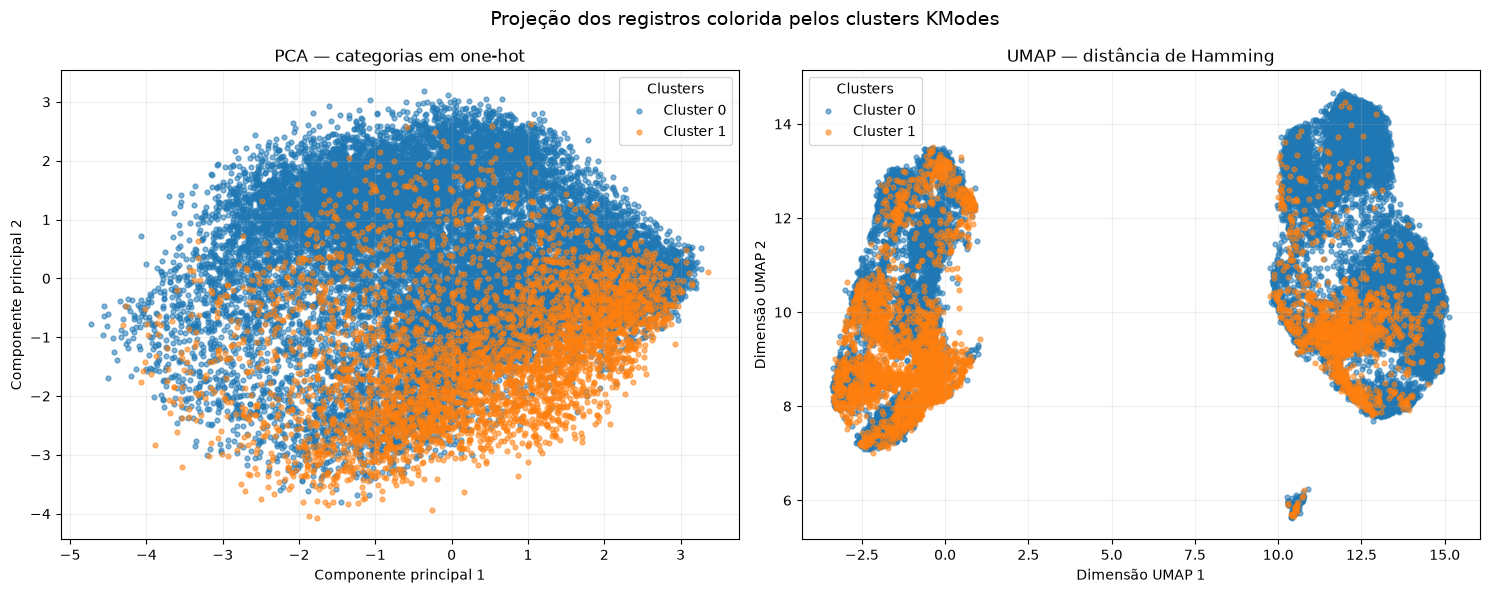

In [8]:
# PCA sobre indicadores one-hot; manter todas as observações e features categóricas.
encoder_pca = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_onehot = encoder_pca.fit_transform(X_categorico)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_onehot)

# Hamming compara categorias por igualdade, sem atribuir ordem ou distância entre códigos.
X_hamming = X_categorico.apply(lambda coluna: pd.factorize(coluna, sort=True)[0])
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="hamming",
    random_state=42,
)
X_umap = reducer.fit_transform(X_hamming)

print(f"Variância explicada pelo PCA (2 componentes): {pca.explained_variance_ratio_.sum():.1%}")
print(f"Dimensões PCA: {X_pca.shape}; dimensões UMAP: {X_umap.shape}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cores = plt.get_cmap("tab10")
for cluster in sorted(labels.unique()):
    mascara = labels.to_numpy() == cluster
    cor = cores(cluster % 10)
    axes[0].scatter(
        X_pca[mascara, 0], X_pca[mascara, 1],
        s=12, alpha=0.55, color=cor, label=f"Cluster {cluster}",
    )
    axes[1].scatter(
        X_umap[mascara, 0], X_umap[mascara, 1],
        s=12, alpha=0.55, color=cor, label=f"Cluster {cluster}",
    )

axes[0].set(title="PCA — categorias em one-hot", xlabel="Componente principal 1", ylabel="Componente principal 2")
axes[1].set(title="UMAP — distância de Hamming", xlabel="Dimensão UMAP 1", ylabel="Dimensão UMAP 2")
for ax in axes:
    ax.legend(title="Clusters")
    ax.grid(alpha=0.2)
fig.suptitle("Projeção dos registros colorida pelos clusters KModes", fontsize=14)
plt.tight_layout()
plt.show()

## PCA seguida de K-means (k=2)

Esta análise alternativa transforma as 58 features categóricas em indicadores one-hot, aplica PCA e agrupa as coordenadas contínuas com K-means (`k=2`). O target de depressão permanece fora do one-hot, do PCA e do ajuste dos clusters; é usado apenas para descrição posterior. A solução principal usa 10 componentes, e a tabela compara também 2, 5 e 15 componentes. Isso é uma comparação exploratória, não uma escolha universal: considere a silhouette, o tamanho/equilíbrio dos grupos, a estabilidade e os perfis nas categorias originais. A silhouette é calculada no espaço PCA e não deve ser comparada diretamente à silhouette de Hamming do KModes.

O one-hot evita atribuir ordem numérica artificial aos códigos das categorias. O PCA, porém, gera coordenadas contínuas; por isso, K-means é usado como agrupador compatível.

PCA: 23,619 registros, 58 variáveis, 269 colunas one-hot.
Sensibilidade ao número de componentes (K-means com k=2):


,componentes_pca,variancia_explicada_acumulada_pct,inercia_kmeans,silhouette_pca_amostra,cluster_menor_pct
0,2,15.341,60666.135,0.381,41.556
1,5,26.768,133619.934,0.221,41.805
2,10,36.641,197051.274,0.164,41.424
3,15,43.901,243823.517,0.137,41.268



Resultado principal: K-means k=2 em 10 componentes PCA.
Tamanho dos clusters:
0     9784
1    13835
Name: registros, dtype: int64

Target por cluster (%; somente descrição posterior):
target      0     1
cluster            
0        76.7  23.3
1        80.3  19.7

Variáveis categóricas originais com maiores diferenças entre os clusters:


,feature,diferenca_total_pct
0,PLANO_PUBLICO,84.0
1,IDADE_FAIXA,79.8
2,FLG_IDOSO_FAMILIA,79.6
3,HISTORICO_HIPERTENSAO,44.5
4,HISTORICO_ARTRITE,42.0
5,DIFICULDADE_LOCOMOCAO,39.4
6,HISTORICO_COLESTEROL,38.3
7,PLANO_PRIVADO,35.1
8,STATUS_PARENTAL,34.8
9,QTD_CRIANÇAS_FAMILIA,34.6


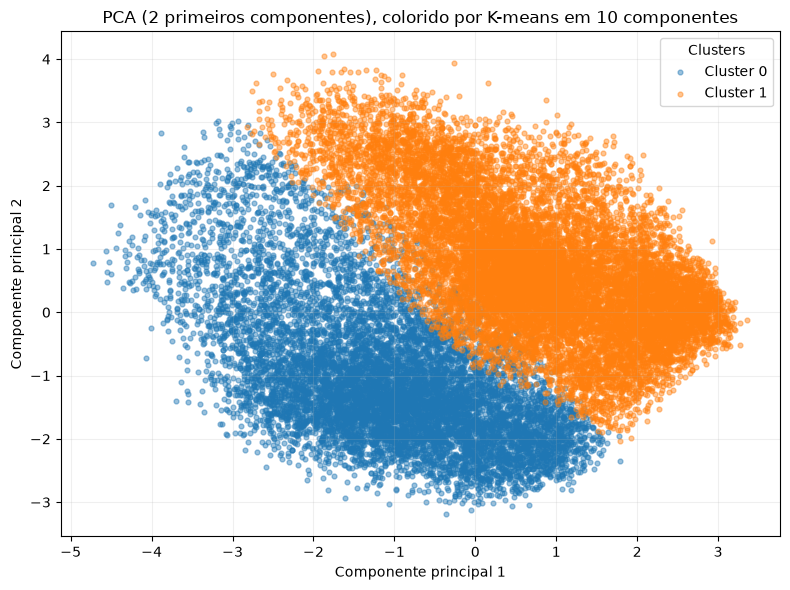

In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

N_COMPONENTES_PCA = 10
DIMENSOES_AVALIADAS = [2, 5, 10, 15]
KMEANS_SEED = 42
n_registros, n_variaveis = X_categorico.shape

# X_onehot foi construído na seção de projeções e contém apenas features, nunca o target.
pca_kmeans = PCA(n_components=max(DIMENSOES_AVALIADAS), svd_solver="randomized", random_state=42)
coordenadas_pca = pca_kmeans.fit_transform(X_onehot)
inercia_explicada_pca = pca_kmeans.explained_variance_ratio_

resultados_sensibilidade = []
modelos_kmeans = {}
for n_componentes in DIMENSOES_AVALIADAS:
    modelo_kmeans = KMeans(n_clusters=2, n_init=20, random_state=KMEANS_SEED)
    rotulos = modelo_kmeans.fit_predict(coordenadas_pca[:, :n_componentes])
    silhouette_pca = silhouette_score(
        coordenadas_pca[:, :n_componentes],
        rotulos,
        sample_size=min(1000, n_registros),
        random_state=KMEANS_SEED,
    )
    contagens = pd.Series(rotulos).value_counts().sort_index()
    resultados_sensibilidade.append({
        "componentes_pca": n_componentes,
        "variancia_explicada_acumulada_pct": 100 * inercia_explicada_pca[:n_componentes].sum(),
        "inercia_kmeans": modelo_kmeans.inertia_,
        "silhouette_pca_amostra": silhouette_pca,
        "cluster_menor_pct": 100 * contagens.min() / n_registros,
    })
    modelos_kmeans[n_componentes] = (modelo_kmeans, rotulos)

print(f"PCA: {n_registros:,} registros, {n_variaveis} variáveis, {X_onehot.shape[1]} colunas one-hot.")
print("Sensibilidade ao número de componentes (K-means com k=2):")
display(pd.DataFrame(resultados_sensibilidade).round(3))

modelo_pca_kmeans, labels_pca_kmeans = modelos_kmeans[N_COMPONENTES_PCA]
tamanho_pca_kmeans = pd.Series(labels_pca_kmeans, index=X_categorico.index).value_counts().sort_index()
resultado_pca_kmeans = pd.DataFrame({"target": y, "cluster": labels_pca_kmeans}, index=X_categorico.index)
target_pca_kmeans = pd.crosstab(
    resultado_pca_kmeans["cluster"], resultado_pca_kmeans["target"], normalize="index"
).mul(100)
print(f"\nResultado principal: K-means k=2 em {N_COMPONENTES_PCA} componentes PCA.")
print("Tamanho dos clusters:")
print(tamanho_pca_kmeans.rename("registros"))
print("\nTarget por cluster (%; somente descrição posterior):")
print(target_pca_kmeans.round(1))

# Compara as distribuições de cada variável categórica original entre os dois grupos.
ranking_pca_kmeans = []
for feature in X_categorico.columns:
    distribuicao = pd.crosstab(
        X_categorico[feature], labels_pca_kmeans, normalize="columns"
    ).reindex(columns=[0, 1], fill_value=0)
    ranking_pca_kmeans.append({
        "feature": feature,
        "diferenca_total_pct": 50 * (distribuicao[0] - distribuicao[1]).abs().sum(),
    })
ranking_pca_kmeans = pd.DataFrame(ranking_pca_kmeans).sort_values(
    "diferenca_total_pct", ascending=False
).reset_index(drop=True)
print("\nVariáveis categóricas originais com maiores diferenças entre os clusters:")
display(ranking_pca_kmeans.head(12).round(1))

fig, ax = plt.subplots(figsize=(8, 6))
for cluster in sorted(np.unique(labels_pca_kmeans)):
    mascara = labels_pca_kmeans == cluster
    ax.scatter(
        coordenadas_pca[mascara, 0], coordenadas_pca[mascara, 1],
        s=12, alpha=0.45, label=f"Cluster {cluster}",
    )
ax.set(title=f"PCA (2 primeiros componentes), colorido por K-means em {N_COMPONENTES_PCA} componentes",
       xlabel="Componente principal 1", ylabel="Componente principal 2")
ax.legend(title="Clusters")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Inspeção do cluster menor e estabilidade

Silhouette alta pode coexistir com um grupo minúsculo, por isso verificamos tamanhos e concordância entre inicializações e números de componentes. O índice ARI compara partições sem depender dos números atribuídos aos clusters; o Jaccard compara diretamente os membros dos clusters menores. Também listamos categorias raras e categorias que aparecem com frequência elevada no grupo pequeno, sempre em contagens agregadas. Estes diagnósticos não provam que o grupo seja um subgrupo clínico.

In [10]:
from itertools import combinations
from sklearn.metrics import adjusted_rand_score

SEMENTES_ESTABILIDADE = [7, 21, 42, 99]
rotulos_por_dimensao = {}
resumo_estabilidade = []
ari_pares = []

for dimensao in DIMENSOES_AVALIADAS:
    rotulos_execucoes = {}
    for semente in SEMENTES_ESTABILIDADE:
        rotulos = KMeans(
            n_clusters=2, n_init=20, random_state=semente
        ).fit_predict(coordenadas_pca[:, :dimensao])
        rotulos_execucoes[semente] = rotulos
    rotulos_por_dimensao[dimensao] = rotulos_execucoes

    ari_intra_dimensao = [
        adjusted_rand_score(rotulos_execucoes[s1], rotulos_execucoes[s2])
        for s1, s2 in combinations(SEMENTES_ESTABILIDADE, 2)
    ]
    tamanhos = [int(np.bincount(rotulos).min()) for rotulos in rotulos_execucoes.values()]
    resumo_estabilidade.append({
        "componentes_pca": dimensao,
        "menor_cluster_min": min(tamanhos),
        "menor_cluster_max": max(tamanhos),
        "menor_cluster_media_pct": 100 * np.mean(tamanhos) / n_registros,
        "ARI_entre_sementes_media": np.mean(ari_intra_dimensao),
        "ARI_entre_sementes_min": np.min(ari_intra_dimensao),
    })
    for s1, s2 in combinations(SEMENTES_ESTABILIDADE, 2):
        ari_pares.append({
            "componentes_pca": dimensao,
            "semente_a": s1,
            "semente_b": s2,
            "ARI": adjusted_rand_score(rotulos_execucoes[s1], rotulos_execucoes[s2]),
        })

print("Estabilidade do K-means para cada número de componentes (ARI próximo de 1 indica partições semelhantes):")
display(pd.DataFrame(resumo_estabilidade).round(3))

# Compara as componentes usando a mesma semente e a sobreposição dos menores grupos.
comparacao_componentes = []
for d1, d2 in combinations(DIMENSOES_AVALIADAS, 2):
    ari_mesma_semente = []
    jaccard_grupos_menores = []
    for semente in SEMENTES_ESTABILIDADE:
        rotulos_a = rotulos_por_dimensao[d1][semente]
        rotulos_b = rotulos_por_dimensao[d2][semente]
        ari_mesma_semente.append(adjusted_rand_score(rotulos_a, rotulos_b))
        menor_a = np.bincount(rotulos_a).argmin()
        menor_b = np.bincount(rotulos_b).argmin()
        conjunto_a = set(np.flatnonzero(rotulos_a == menor_a))
        conjunto_b = set(np.flatnonzero(rotulos_b == menor_b))
        jaccard_grupos_menores.append(
            len(conjunto_a & conjunto_b) / len(conjunto_a | conjunto_b)
        )
    comparacao_componentes.append({
        "componentes_comparadas": f"{d1} vs {d2}",
        "ARI_media_mesma_semente": np.mean(ari_mesma_semente),
        "Jaccard_menor_cluster_medio": np.mean(jaccard_grupos_menores),
    })
print("\nConcordância entre diferentes números de componentes:")
display(pd.DataFrame(comparacao_componentes).round(3))

# Perfil agregado do cluster menor em cada componente, incluindo taxa do target apenas para descrição.
perfis_menores = []
membros_menores = {}
for dimensao in DIMENSOES_AVALIADAS:
    rotulos = modelos_kmeans[dimensao][1]
    menor = np.bincount(rotulos).argmin()
    mascara = rotulos == menor
    membros_menores[dimensao] = set(np.flatnonzero(mascara))
    prevalencia_target = y.iloc[np.flatnonzero(mascara)].mean() * 100
    perfis_menores.append({
        "componentes_pca": dimensao,
        "cluster_menor_id": int(menor),
        "registros": int(mascara.sum()),
        "percentual_amostra": 100 * mascara.mean(),
        "target_positivo_pct": prevalencia_target,
    })
print("\nTamanho e target dos grupos menores na execução de referência:")
display(pd.DataFrame(perfis_menores).round(2))

jaccards_referencia = []
for d1, d2 in combinations(DIMENSOES_AVALIADAS, 2):
    a, b = membros_menores[d1], membros_menores[d2]
    jaccards_referencia.append({
        "componentes_comparadas": f"{d1} vs {d2}",
        "Jaccard_menor_cluster": len(a & b) / len(a | b),
        "registros_em_comum": len(a & b),
    })
print("\nSobreposição dos grupos menores entre componentes (execução de referência):")
display(pd.DataFrame(jaccards_referencia).round(3))

# Mede a concentração do código -1 (não-resposta/indeterminado) no grupo menor e no restante.
dimensao_inspecao = 10
rotulos_inspecao = modelos_kmeans[dimensao_inspecao][1]
cluster_menor_inspecao = np.bincount(rotulos_inspecao).argmin()
mascara_menor = rotulos_inspecao == cluster_menor_inspecao
quantidade_nao_respostas = X_categorico.eq("-1").sum(axis=1)
resumo_nao_respostas = pd.DataFrame({
    "grupo": np.where(mascara_menor, "cluster menor", "demais registros"),
    "quantidade_features_com_-1": quantidade_nao_respostas.to_numpy(),
}).groupby("grupo")["quantidade_features_com_-1"].agg(
    registros="size", media="mean", mediana="median", maximo="max",
    com_5_ou_mais=lambda valores: (valores >= 5).mean() * 100,
).rename(columns={"com_5_ou_mais": "com_5_ou_mais_pct"})
print("Concentração de códigos -1 por registro (em 58 features categóricas):")
display(resumo_nao_respostas.round(2))

# Inspeciona categorias raras no grupo de referência de 10 componentes, sem expor registros individuais.
categorias_menor = []
for feature in X_categorico.columns:
    dados_feature = X_categorico[feature].astype(str)
    tabela = pd.crosstab(dados_feature, rotulos_inspecao)
    for categoria, linha in tabela.iterrows():
        total_categoria = int(linha.sum())
        contagem_menor = int(linha.get(cluster_menor_inspecao, 0))
        if contagem_menor < 5:
            continue
        pct_menor = 100 * contagem_menor / int(mascara_menor.sum())
        pct_amostra = 100 * total_categoria / n_registros
        categorias_menor.append({
            "feature": feature,
            "categoria": categoria,
            "n_no_cluster_menor": contagem_menor,
            "pct_cluster_menor": pct_menor,
            "pct_amostra_total": pct_amostra,
            "diferenca_pp": pct_menor - pct_amostra,
        })
categorias_menor = pd.DataFrame(categorias_menor)
categorias_raras = categorias_menor[
    (categorias_menor["pct_amostra_total"] <= 2)
    & (categorias_menor["pct_cluster_menor"] >= 5)
].sort_values(["pct_cluster_menor", "n_no_cluster_menor"], ascending=False)
print(f"\nCategorias raras enriquecidas no cluster menor de {dimensao_inspecao} componentes (mínimo 5 ocorrências):")
if categorias_raras.empty:
    print("Nenhuma categoria atende simultaneamente aos critérios de raridade e concentração definidos.")
else:
    display(categorias_raras.head(20).round(2))

print("\nCategorias mais concentradas no cluster menor, independentemente da raridade global:")
display(categorias_menor.sort_values("diferenca_pp", ascending=False).head(20).round(2))

Estabilidade do K-means dentro de cada componente (ARI próximo de 1 indica partições semelhantes):


,componentes_pca,menor_cluster_min,menor_cluster_max,menor_cluster_media_pct,ARI_entre_sementes_media,ARI_entre_sementes_min
0,2,9793,9815,41.517,0.994,0.990
1,5,9872,9876,41.805,0.999,0.999
2,10,9779,9784,41.415,0.999,0.998
3,15,9747,9751,41.279,0.999,0.998



Concordância entre diferentes números de componentes:


,componentes_comparadas,ARI_media_mesma_semente,Jaccard_menor_cluster_medio
0,2 vs 5,0.915,0.949
1,2 vs 10,0.904,0.943
2,2 vs 15,0.904,0.942
3,5 vs 10,0.959,0.975
4,5 vs 15,0.955,0.973
5,10 vs 15,0.991,0.994



Tamanho e target dos grupos menores na execução de referência:


...

,componentes_comparadas,Jaccard_menor_cluster,registros_em_comum
0,2 vs 5,0.949,9586
1,2 vs 10,0.942,9505
2,2 vs 15,0.941,9486
3,5 vs 10,0.975,9704
4,5 vs 15,0.972,9673
5,10 vs 15,0.994,9737


Concentração de códigos -1 por registro (em 58 features categóricas):


,registros,media,mediana,maximo,com_5_ou_mais_pct
grupo,,,,,
cluster menor,9784,0.19,0.0,19,1.23
demais registros,13835,0.16,0.0,20,1.13



Categorias raras enriquecidas no cluster menor de 10 componentes (mínimo 5 ocorrências):
Nenhuma categoria atende simultaneamente aos critérios de raridade e concentração definidos.

Categorias mais concentradas no cluster menor, independentemente da raridade global:


,feature,categoria,n_no_cluster_menor,pct_cluster_menor,pct_amostra_total,diferenca_pp
160,PLANO_PUBLICO,1,8327,85.11,35.92,49.19
36,FLG_IDOSO_FAMILIA,1,8493,86.80,40.20,46.60
91,HISTORICO_HIPERTENSAO,1,6318,64.57,38.52,26.05
94,HISTORICO_ARTRITE,1,5015,51.26,26.76,24.50
253,IDADE_FAIXA,60-74,5099,52.12,27.90,24.21
254,IDADE_FAIXA,75+,3774,38.57,16.08,22.49
85,HISTORICO_COLESTEROL,1,5535,56.57,34.24,22.33
164,PLANO_PRIVADO,2,5712,58.38,37.83,20.56
25,STATUS_PARENTAL,3,9467,96.76,76.46,20.30
40,QTD_CRIANÇAS_FAMILIA,0,9468,96.77,76.53,20.24


### Leitura dos diagnósticos

Com 10 componentes, o K-means formou grupos bem mais equilibrados: 9.784 (41,4%) e 13.835 registros (58,6%). A estabilidade também foi alta neste teste: entre sementes, ARI médio de 0,999; entre soluções de 10 e 15 componentes, ARI médio de 0,991 e Jaccard médio de 0,994 para o menor grupo. Os perfis nas categorias originais apontam principalmente contraste de idade e cobertura Medicare: 85,1% do grupo menor estão na categoria `PLANO_PUBLICO = 1`, contra 35,9% da amostra; 52,1% estão na faixa de 60–74 anos e 38,6% na de 75 anos ou mais. Confirme o significado dos códigos no codebook antes de rotulá-los em texto.

A prevalência observada do target é 23,3% no grupo menor e 19,7% no maior, diferença descritiva de 3,6 pontos percentuais. Isso não demonstra capacidade de prever casos futuros nem causalidade. A fração de pessoas com pelo menos cinco códigos `-1` é semelhante nos dois grupos (1,23% e 1,13%), portanto, ao contrário da solução anterior, o cluster menor não parece ser apenas um grupo de não resposta.

A silhouette mais alta apareceu com 2 componentes (0,381), mas essa configuração explica 15,3% da variância; 10 componentes explicam 36,6% e 15 explicam 43,9%. A redução da silhouette com mais componentes não é motivo suficiente para escolher 2. Compare as soluções junto da estabilidade, tamanhos e interpretação das categorias originais; mantenha o target fora da escolha.